# Chapter 38 — Value at Risk and Expected Shortfall

Every number in the chapter's worked examples, tables and figures, recomputed in order. The code uses **NumPy, SciPy and
Matplotlib**, with three exceptions where exact reproduction matters: the simulated windows of Examples 38.3 and
38.7 are drawn with Python's own `random.Random(seed).random()` and built by hand, because that generator gives
the same numbers on every machine and every version, which `random.gauss` and NumPy's generators do not promise;
and the scatter of Figure 38.5 uses `random.Random(38)`, so its corner counts match the chapter's.

Each figure is printed beside the chapter's value with `ok` or `DIFFERS`; the last cell lists any that differ.

| Section | What it reproduces | Example / Figure |
|---|---|---|
| 1 | VaR and ES of a normal book; ES at 97.5% against VaR at 99% | 38.1, Figure 38.1 |
| 2 | Two bonds that break subadditivity | 38.2 |
| 3 | Historical simulation, age weighting, and the sampling error of a quantile | 38.3 |
| 4 | Variance–covariance VaR on two stocks | 38.4 |
| 5 | Sold puts: the delta–gamma expansion, Cornish–Fisher, Monte Carlo sampling error | 38.5, Section 38.7 |
| 6 | The same volatility, a fat tail | 38.6, Figure 38.2 |
| 7 | Three estimators of a quantile beyond the data, one window and 400 | 38.7, Figure 38.3 |
| 8 | EWMA against GARCH after one bad day | 38.8, Figure 38.4 |
| 9 | VaR as a function of correlation | 38.9 |
| 10 | Gaussian against $t$ copula: joint tails, tail dependence, a scatter | 38.10, Figure 38.5 |
| 11 | Factor reduction on a stated covariance | 38.11, Figure 38.6 |
| 12 | Scaling to ten days under autocorrelation; the stressed book | Sections 38.14, 38.18 |
| 13 | Component, marginal and incremental VaR | 38.12 |
| 14 | Backtesting: exceptions, Kupiec, the traffic light | 38.13, Figure 38.7 |
| 15 | Stress testing and reverse stress testing | 38.14, 38.15, Figure 38.8 |
| 16 | Twenty-five sigma, several days running | Case study |

The helpers below are used throughout. `show` prints a computed figure beside the chapter's, with a tolerance
that matches the printed rounding.

In [1]:
import random
from math import cos, exp, log, log1p, expm1, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t as student_t, binom, chi2
from scipy.integrate import quad

N, phi, Ninv = norm.cdf, norm.pdf, norm.ppf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one, told apart by dash pattern as well as color.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """A figure beside the chapter's. `tol` is absolute and matches the printed rounding."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-50s %12.4f   book %11.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))

## 1. Two measures on the same book — Example 38.1

A \$100m position with a 2.0% daily standard deviation, so the one-day loss is normal with $\sigma = \$2$m. For a
normal loss,

$$\mathrm{VaR}_c = z_c\,\sigma, \qquad \mathrm{ES}_c = \sigma\,\frac{N'(z_c)}{1-c},$$

with $z_c = N^{-1}(c)$. The ratio ES/VaR falls toward one as $c$ rises: a thin tail has little beyond its quantile.

In [2]:
SD = 2.0                                    # $m
print("%-8s %8s %10s %10s %8s" % ("c", "z", "VaR $m", "ES $m", "ES/VaR"))
for c, zp, varp, esp, ratp in ((0.95, 1.6449, 3.29, 4.13, 1.254), (0.975, 1.9600, 3.92, 4.68, 1.193),
                               (0.99, 2.3263, 4.65, 5.33, 1.146), (0.999, 3.0902, 6.18, 6.73, 1.090)):
    z = Ninv(c)
    es_z = phi(z) / (1 - c)
    print("%-8.3f %8.4f %10.2f %10.2f %8.3f" % (c, z, SD * z, SD * es_z, es_z / z))
    show("  z at %.1f%%" % (100 * c), z, zp, 5e-5)
    show("  VaR ($m)", SD * z, varp, 5e-3)
    show("  ES ($m)", SD * es_z, esp, 5e-3)
    show("  ES / VaR", es_z / z, ratp, 5e-4)

z99, z975 = Ninv(0.99), Ninv(0.975)
es975 = phi(z975) / 0.025
show("VaR 99% in sigmas", z99, 2.3263, 5e-5)
show("ES 97.5% in sigmas", es975, 2.3378, 5e-5)
show("ratio ES 97.5% / VaR 99%", es975 / z99, 1.0049, 5e-5)

c               z     VaR $m      ES $m   ES/VaR
0.950      1.6449       3.29       4.13    1.254
  z at 95.0%                                             1.6449   book      1.6449   ok
  VaR ($m)                                               3.2897   book      3.2900   ok
  ES ($m)                                                4.1254   book      4.1300   ok
  ES / VaR                                               1.2540   book      1.2540   ok
0.975      1.9600       3.92       4.68    1.193
  z at 97.5%                                             1.9600   book      1.9600   ok
  VaR ($m)                                               3.9199   book      3.9200   ok
  ES ($m)                                                4.6756   book      4.6800   ok
  ES / VaR                                               1.1928   book      1.1930   ok
0.990      2.3263       4.65       5.33    1.146
  z at 99.0%                                             2.3263   book      2.3263   ok
  VaR ($m)  

**Figure 38.1.** Left: the standard normal, with VaR and ES at 99%. Right: a distribution identical to the
normal below the VaR, but with half its 1% tail moved into a lump at $7\sigma$ (a normal with mean 7 and
standard deviation 0.6). The VaR cannot see the change; the ES nearly doubles.

left: ES 99% in sigmas                                   2.6652   book      2.6652   ok
right: mass beyond the VaR (unchanged)                   0.0100   book      0.0100   ok
right: ES in sigmas                                      4.8326   book      4.8300   ok


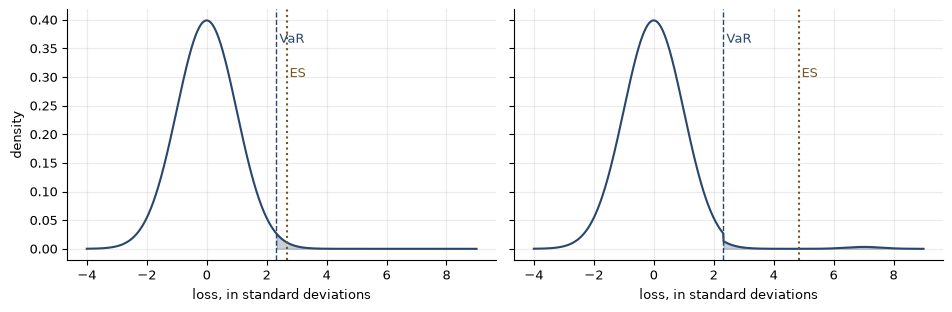

In [3]:
show("left: ES 99% in sigmas", phi(z99) / 0.01, 2.6652, 5e-5)
tail_mass = 0.5 * (1 - N(z99)) + 0.005 * (1 - N((z99 - 7) / 0.6))
show("right: mass beyond the VaR (unchanged)", tail_mass, 0.01, 1e-6)
es_right = (0.5 * phi(z99) + 0.005 * 7) / 0.01
show("right: ES in sigmas", es_right, 4.83, 5e-3)

x = np.linspace(-4, 9, 1301)
dens_right = np.where(x < z99, phi(x), 0.5 * phi(x) + 0.005 * norm.pdf(x, 7, 0.6))
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), sharey=True)
for ax, d, es in ((axes[0], phi(x), phi(z99) / 0.01), (axes[1], dens_right, es_right)):
    ax.plot(x, d, color=BLUE)
    ax.fill_between(x, 0, d, where=x >= z99, color=BLUE, alpha=0.25)
    ax.axvline(z99, color=BLUE, ls="--", lw=1)
    ax.axvline(es, color=AMBER, ls=":", lw=1.5)
    ax.set_xlabel("loss, in standard deviations")
    ax.text(z99 + 0.1, 0.36, "VaR", color=BLUE)
    ax.text(es + 0.1, 0.30, "ES", color=AMBER)
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

## 2. Two bonds that break the measure — Example 38.2

Two independent \$10m bonds, each defaulting with probability 0.8% and recovering nothing, measured at 99%.
One bond's VaR is zero, since 99.2% of the mass sits at no loss; the pair's is \$10m. VaR is not subadditive here.
Expected shortfall is, because it counts the share of an atom that falls inside the worst 1%.

In [4]:
def var_es(dist, c):
    """dist: list of (loss, prob). VaR is the lower quantile; ES averages the worst 1 - c of mass,
    taking only the needed share of the atom at the quantile."""
    cum, var = 0.0, None
    for L, q in sorted(dist):
        cum += q
        if cum >= c - 1e-15:
            var = L
            break
    tail, left = 0.0, 1 - c
    for L, q in sorted(dist, reverse=True):
        take = min(q, left)
        tail += take * L
        left -= take
        if left <= 1e-15:
            break
    return var, tail / (1 - c)


p = 0.008
p0, p1, p2 = (1 - p) ** 2, 2 * p * (1 - p), p * p
show("P(loss 0)", p0, 0.984064, 5e-7)
show("P(loss 10)", p1, 0.015872, 5e-7)
show("P(loss 20)", p2, 0.000064, 5e-7)
v1, e1 = var_es([(0, 1 - p), (10, p)], 0.99)
v2, e2 = var_es([(0, p0), (10, p1), (20, p2)], 0.99)
show("VaR 99%, one bond ($m)", v1, 0.0, 1e-9)
show("VaR 99%, the pair ($m)", v2, 10.0, 1e-9)
show("ES 99%, one bond ($m)", e1, 8.0, 5e-3)
show("ES 99%, the pair ($m)", e2, 10.06, 5e-3)
show("sum of standalone ES ($m)", 2 * e1, 16.0, 5e-3)

P(loss 0)                                                0.9841   book      0.9841   ok
P(loss 10)                                               0.0159   book      0.0159   ok
P(loss 20)                                               0.0001   book      0.0001   ok
VaR 99%, one bond ($m)                                   0.0000   book      0.0000   ok
VaR 99%, the pair ($m)                                  10.0000   book     10.0000   ok
ES 99%, one bond ($m)                                    8.0000   book      8.0000   ok
ES 99%, the pair ($m)                                   10.0640   book     10.0600   ok
sum of standalone ES ($m)                               16.0000   book     16.0000   ok


## 3. Five losses out of five hundred — Example 38.3

A \$10m equity index position and 500 days of history. The returns are simulated: a Student's $t$ with four
degrees of freedom scaled to a 1.25% daily standard deviation, drawn from a fixed seed. Element $k$ of the
window is the scenario $k+1$ days ago, applied to today's position.

Equal weighting puts the 99% VaR at the sixth-worst loss (five losses, 1% of 500, lie beyond it) and the ES at
the mean of the five worst. Age weighting with $\lambda = 0.995$ gives the scenario $i$ days old a weight
proportional to $\lambda^i$. The example runs it twice, on the window as recorded and on the same window with
its dates reversed, to show that the answer depends on *when* the bad days happened.

In [5]:
def hs_window(seed=20261016, n=500, pos=10.0, sd=0.0125):
    """Scenario losses in $000; element k is the scenario k+1 days ago. Returns are t(4)
    rescaled to the stated daily standard deviation (a t(4) has variance 2)."""
    rng = random.Random(seed)
    out = []
    for _ in range(n):
        u1, u2 = 1.0 - rng.random(), rng.random()
        z = sqrt(-2 * log(u1)) * cos(2 * pi * u2)
        w = -2 * log((1.0 - rng.random()) * (1.0 - rng.random()))      # chi-squared, 4 d.f.
        out.append(-pos * sd * sqrt(0.5) * z / sqrt(w / 4.0) * 1000.0)
    return out


def weighted_var(losses, ages, lam=0.995, c=0.99):
    """Count down from the worst loss; the VaR is the first at which the running weight passes 1 - c."""
    ws = [lam ** a for a in ages]
    tot = sum(ws)
    ws = [x / tot for x in ws]
    run = 0.0
    for rank, k in enumerate(sorted(range(len(losses)), key=lambda j: -losses[j])):
        run += ws[k]
        if run > (1 - c) + 1e-12:
            return losses[k], rank + 1, ws


H = hs_window()
ages = list(range(1, 501))
rev = [501 - a for a in ages]
order = sorted(range(500), key=lambda j: -H[j])
_, _, w_rec = weighted_var(H, ages)
_, _, w_rev = weighted_var(H, rev)

print("%-5s %10s %9s %10s %9s %10s" % ("Rank", "Loss $000", "Days ago", "Weight %", "Reversed", "Weight %"))
book = ((581, 428, 0.064, 73, 0.379), (437, 458, 0.055, 43, 0.441), (424, 446, 0.059, 55, 0.415),
        (408, 249, 0.157, 252, 0.155), (396, 442, 0.060, 59, 0.407), (357, 383, 0.080, 118, 0.303))
for r, (L_p, age_p, w_p, agr_p, wr_p) in enumerate(book):
    k = order[r]
    print("%-5d %10.0f %9d %10.3f %9d %10.3f" % (r + 1, H[k], k + 1, 100 * w_rec[k], rev[k], 100 * w_rev[k]))
    show("  rank %d loss ($000)" % (r + 1), H[k], L_p, 0.5)
    show("  rank %d days ago" % (r + 1), k + 1, age_p, 0)
    show("  rank %d weight as recorded (%%)" % (r + 1), 100 * w_rec[k], w_p, 5e-4)
    show("  rank %d weight reversed (%%)" % (r + 1), 100 * w_rev[k], wr_p, 5e-4)

Rank   Loss $000  Days ago   Weight %  Reversed   Weight %
1            581       428      0.064        73      0.379
  rank 1 loss ($000)                                   581.1358   book    581.0000   ok
  rank 1 days ago                                      428.0000   book    428.0000   ok
  rank 1 weight as recorded (%)                          0.0640   book      0.0640   ok
  rank 1 weight reversed (%)                             0.3795   book      0.3790   ok
2            437       458      0.055        43      0.441
  rank 2 loss ($000)                                   436.5712   book    437.0000   ok
  rank 2 days ago                                      458.0000   book    458.0000   ok
  rank 2 weight as recorded (%)                          0.0551   book      0.0550   ok
  rank 2 weight reversed (%)                             0.4411   book      0.4410   ok
3            424       446      0.059        55      0.415
  rank 3 loss ($000)                                   423.9

In [6]:
hs_var, hs_es = var_es([(x, 1 / 500.0) for x in H], 0.99)
show("equal-weight 99% VaR, the sixth-worst ($000)", hs_var, 357, 0.5)
show("equal-weight 99% ES, mean of five worst ($000)", hs_es, 449, 0.5)
show("fifth-worst above sixth-worst (%)", 100 * (H[order[4]] / hs_var - 1), 11, 0.5)
show("weight of yesterday (%)", 100 * w_rec[0], 0.544, 5e-4)
show("weight of the oldest day (%)", 100 * w_rec[499], 0.045, 5e-4)
show("five worst, weight as recorded (%)", 100 * sum(w_rec[k] for k in order[:5]), 0.394, 5e-4)
wv, wrank, _ = weighted_var(H, ages)
show("weighted VaR as recorded: rank", wrank, 12, 0)
show("weighted VaR as recorded ($000)", wv, 287, 0.5)
show("  below equal weighting (%)", 100 * (1 - wv / hs_var), 20, 0.5)
wv2, wrank2, _ = weighted_var(H, rev)
show("weighted VaR reversed: rank", wrank2, 3, 0)
show("  three worst carry (%)", 100 * sum(w_rev[k] for k in order[:3]), 1.24, 5e-3)
show("weighted VaR reversed ($000)", wv2, 424, 0.5)
show("  above equal weighting (%)", 100 * (wv2 / hs_var - 1), 19, 0.5)
show("largest loss, the cap on any weighting ($000)", max(H), 581, 0.5)

# The sampling error of a quantile estimate, sqrt(c(1-c)/n) / f(q), for this book's true distribution.
hs_scale = 10 * 0.0125 * sqrt(0.5) * 1000              # $000 per unit of a standard t(4)
hs_q = student_t.ppf(0.99, 4)
hs_true = hs_scale * hs_q
hs_se = sqrt(0.01 * 0.99 / 500) / (student_t.pdf(hs_q, 4) / hs_scale)
show("true 99% VaR of this book ($000)", hs_true, 331, 0.5)
show("standard error of a 500-day estimate ($000)", hs_se, 45, 0.5)
show("  as a share of the answer (%)", 100 * hs_se / hs_true, 14, 0.5)
show("the example's VaR from the truth, in standard errors", (hs_var - hs_true) / hs_se, 0.56, 5e-3)

equal-weight 99% VaR, the sixth-worst ($000)           356.6243   book    357.0000   ok
equal-weight 99% ES, mean of five worst ($000)         449.2265   book    449.0000   ok
fifth-worst above sixth-worst (%)                       11.1049   book     11.0000   ok
weight of yesterday (%)                                  0.5444   book      0.5440   ok
weight of the oldest day (%)                             0.0446   book      0.0450   ok
five worst, weight as recorded (%)                       0.3944   book      0.3940   ok
weighted VaR as recorded: rank                          12.0000   book     12.0000   ok
weighted VaR as recorded ($000)                        286.7312   book    287.0000   ok
  below equal weighting (%)                             19.5985   book     20.0000   ok
weighted VaR reversed: rank                              3.0000   book      3.0000   ok
  three worst carry (%)                                  1.2358   book      1.2400   ok
weighted VaR reversed ($000)    

## 4. Two stocks — Example 38.4

\$10m in a stock with 2.0% daily volatility and \$5m in one with 1.0%, correlation 0.3. With $\sigma_1$, $\sigma_2$ the positions' dollar standard deviations, the portfolio's dollar
standard deviation is $\sigma_P = \sqrt{\sigma_1^2 + \sigma_2^2 + 2\rho\sigma_1\sigma_2}$, and the
99% VaR is $2.3263\,\sigma_P$.

In [7]:
d1, d2, rho = 10 * 0.020, 5 * 0.010, 0.3          # dollar standard deviations, $m
sP = sqrt(d1 * d1 + d2 * d2 + 2 * rho * d1 * d2)
show("variance ($m^2)", sP ** 2, 0.0485, 1e-12)
show("sigma_P ($m)", sP, 0.2202, 5e-5)
show("1-day 99% VaR ($m)", z99 * sP, 0.512, 5e-4)
show("10-day VaR, square-root rule ($m)", z99 * sP * sqrt(10), 1.620, 5e-4)
show("standalone VaR, stock 1 ($m)", z99 * d1, 0.465, 5e-4)
show("standalone VaR, stock 2 ($m)", z99 * d2, 0.116, 5e-4)
show("diversification benefit ($m)", z99 * (d1 + d2 - sP), 0.069, 5e-4)
show("diversification benefit (%)", 100 * (1 - sP / (d1 + d2)), 11.9, 0.05)

variance ($m^2)                                          0.0485   book      0.0485   ok
sigma_P ($m)                                             0.2202   book      0.2202   ok
1-day 99% VaR ($m)                                       0.5123   book      0.5120   ok
10-day VaR, square-root rule ($m)                        1.6201   book      1.6200   ok
standalone VaR, stock 1 ($m)                             0.4653   book      0.4650   ok
standalone VaR, stock 2 ($m)                             0.1163   book      0.1160   ok
diversification benefit ($m)                             0.0693   book      0.0690   ok
diversification benefit (%)                             11.9091   book     11.9000   ok


## 5. Sold puts on the same stock — Example 38.5 and Section 38.7

The position in the first stock held through sold puts, with dollar delta \$10m and dollar gamma $-\$100$m,
valued by the delta–gamma expansion at the stock's 99% fall, $r = -2.3263 \times 2.0\%$:

$$\Delta V \approx \Delta_\$\, r + \frac{1}{2}\,\Gamma_\$\, r^2 .$$

Section 38.7 then summarizes the same loss two ways. Cornish–Fisher corrects the normal quantile for the loss's
skewness $\gamma_1$ and excess kurtosis $\gamma_2$. Monte Carlo draws the return many times; its sampling error is
the quantile standard error with $M$ draws, $\sqrt{c(1-c)/M}/f$, where $f$ is the loss density at the VaR,
the return's density divided by $\lvert dL/dr \rvert = \lvert -10 + 100\,r\rvert$.

In [8]:
dd, gg = 10.0, -100.0                              # dollar delta, dollar gamma, $m
r99 = -z99 * 0.020
lin, quad_ = -dd * r99, -0.5 * gg * r99 ** 2
show("stock 1's 99% fall (%)", 100 * r99, -4.653, 5e-4)
show("linear (delta) loss ($m)", lin, 0.4653, 5e-5)
show("gamma addition ($m)", quad_, 0.1082, 5e-5)
show("delta-gamma loss ($m)", lin + quad_, 0.5735, 5e-5)
show("  increase over linear (%)", 100 * quad_ / lin, 23, 0.5)
show("rise at which the position first loses (%)", 100 * (-2 * dd / gg), 20, 1e-9)
show("  in standard deviations", (-2 * dd / gg) / 0.020, 10, 1e-9)

# Cornish-Fisher on the loss L = -10 r + 50 r^2, r ~ N(0, 0.02^2): moments in closed form.
ca, cb, cs = -dd, -0.5 * gg, 0.020
c_mu = cb * cs ** 2
c_var = ca ** 2 * cs ** 2 + 2 * cb ** 2 * cs ** 4
c_g1 = (6 * ca ** 2 * cb * cs ** 4 + 8 * cb ** 3 * cs ** 6) / c_var ** 1.5
c_g2 = (48 * ca ** 2 * cb ** 2 * cs ** 6 + 48 * cb ** 4 * cs ** 8) / c_var ** 2
z_cf3 = z99 + (z99 ** 2 - 1) * c_g1 / 6
z_cf4 = z_cf3 + (z99 ** 3 - 3 * z99) * c_g2 / 24 - (2 * z99 ** 3 - 5 * z99) * c_g1 ** 2 / 36
show("loss mean ($m)", c_mu, 0.020, 5e-4)
show("loss standard deviation ($m)", sqrt(c_var), 0.2020, 5e-5)
show("loss skewness", c_g1, 0.590, 5e-4)
show("loss excess kurtosis", c_g2, 0.466, 5e-4)
show("normal quantile on two moments ($m)", c_mu + z99 * sqrt(c_var), 0.490, 5e-4)
show("Cornish-Fisher, skewness ($m)", c_mu + z_cf3 * sqrt(c_var), 0.578, 5e-4)
show("Cornish-Fisher, with kurtosis ($m)", c_mu + z_cf4 * sqrt(c_var), 0.573, 5e-4)
# exact: P(L > x) from the two roots of a r + b r^2 = x
from scipy.optimize import brentq
tail = lambda x: (N((-ca - sqrt(ca * ca + 4 * cb * x)) / (2 * cb) / cs)
                  + norm.sf((-ca + sqrt(ca * ca + 4 * cb * x)) / (2 * cb) / cs))
show("exact 99% quantile of the loss ($m)", brentq(lambda x: tail(x) - 0.01, 0.1, 2.0), 0.5735, 5e-5)

# Monte Carlo sampling error of the 99% quantile (Section 38.7).
dLdr = abs(-dd - gg * r99)
f_L = phi(z99) / 0.020 / dLdr
show("|dL/dr| at the 99% fall", dLdr, 14.653, 5e-4)
show("loss density at the VaR (per $m)", f_L, 0.0909, 5e-5)
for M, rel_p in ((10000, 1.9), (100000, 0.6)):
    se_mc = sqrt(0.99 * 0.01 / M) / f_L
    show("  s.e. with %d draws, share of VaR (%%)" % M, 100 * se_mc / (lin + quad_), rel_p, 0.05)
# The formula against an actual simulation: 300 runs of 10,000 draws each (illustrative, NumPy's generator).
gen = np.random.default_rng(38)
runs = [np.quantile(-dd * r - 0.5 * gg * r * r, 0.99) for r in gen.normal(0, 0.020, (300, 10000))]
print("300 Monte Carlo runs of 10,000 draws: VaR spread %.4f against the formula's %.4f ($m)" % (np.std(runs, ddof=1), sqrt(0.0099 / 10000) / f_L))

stock 1's 99% fall (%)                                  -4.6527   book     -4.6530   ok
linear (delta) loss ($m)                                 0.4653   book      0.4653   ok
gamma addition ($m)                                      0.1082   book      0.1082   ok
delta-gamma loss ($m)                                    0.5735   book      0.5735   ok
  increase over linear (%)                              23.2635   book     23.0000   ok
rise at which the position first loses (%)              20.0000   book     20.0000   ok
  in standard deviations                                10.0000   book     10.0000   ok
loss mean ($m)                                           0.0200   book      0.0200   ok
loss standard deviation ($m)                             0.2020   book      0.2020   ok
loss skewness                                            0.5902   book      0.5900   ok
loss excess kurtosis                                     0.4660   book      0.4660   ok
normal quantile on two moments (

## 6. The same volatility, a different shape — Example 38.6

The book of Example 38.1 again, with the normal replaced by a Student's $t$ with four degrees of freedom scaled
to the same 2.0% standard deviation (a $t_4$ has variance 2, so the scale is $2\sqrt{1/2}$). For a standard
$t_\nu$ the tail mean beyond the quantile $q$ is

$$\mathrm{ES} = \frac{f_\nu(q)}{1-c}\cdot\frac{\nu + q^2}{\nu - 1},$$

so both measures are exact; nothing here is simulated.

In [9]:
SCALE = SD * sqrt((4 - 2) / 4.0)


def t4_var_es(c):
    q = student_t.ppf(c, 4)
    return SCALE * q, SCALE * student_t.pdf(q, 4) / (1 - c) * (4 + q * q) / 3.0


print("%-7s %10s %10s %10s %10s %9s" % ("c", "VaR norm", "VaR t4", "ES norm", "ES t4", "ES rise %"))
for c, vn_p, vt_p, en_p, et_p, err_p in ((0.95, 3.29, 3.01, 4.13, 4.53, 10),
                                         (0.99, 4.65, 5.30, 5.33, 7.38, 39),
                                         (0.999, 6.18, 10.14, 6.73, 13.70, 103)):
    vt, et = t4_var_es(c)
    vn, en = SD * Ninv(c), SD * phi(Ninv(c)) / (1 - c)
    print("%-7.3f %10.2f %10.2f %10.2f %10.2f %9.0f" % (c, vn, vt, en, et, 100 * (et / en - 1)))
    show("  normal VaR %.1f%% ($m)" % (100 * c), vn, vn_p, 5e-3)
    show("  t(4) VaR ($m)", vt, vt_p, 5e-3)
    show("  normal ES ($m)", en, en_p, 5e-3)
    show("  t(4) ES ($m)", et, et_p, 5e-3)
    show("  ES rise over the normal (%)", 100 * (et / en - 1), err_p, 0.5)
show("95% VaR: the t below the normal (%)", 100 * (1 - t4_var_es(0.95)[0] / (SD * Ninv(0.95))), 8, 0.5)
VAR_TRUE, ES_TRUE = t4_var_es(0.999)

c         VaR norm     VaR t4    ES norm      ES t4  ES err %
0.950         3.29       3.01       4.13       4.53        10
  normal VaR 95.0% ($m)                                  3.2897   book      3.2900   ok
  t(4) VaR ($m)                                          3.0149   book      3.0100   ok
  normal ES ($m)                                         4.1254   book      4.1300   ok
  t(4) ES ($m)                                           4.5295   book      4.5300   ok
  ES error of the normal (%)                             9.7958   book     10.0000   ok
0.990         4.65       5.30       5.33       7.38        39
  normal VaR 99.0% ($m)                                  4.6527   book      4.6500   ok
  t(4) VaR ($m)                                          5.2990   book      5.3000   ok
  normal ES ($m)                                         5.3304   book      5.3300   ok
  t(4) ES ($m)                                           7.3830   book      7.3800   ok
  ES error of the norm

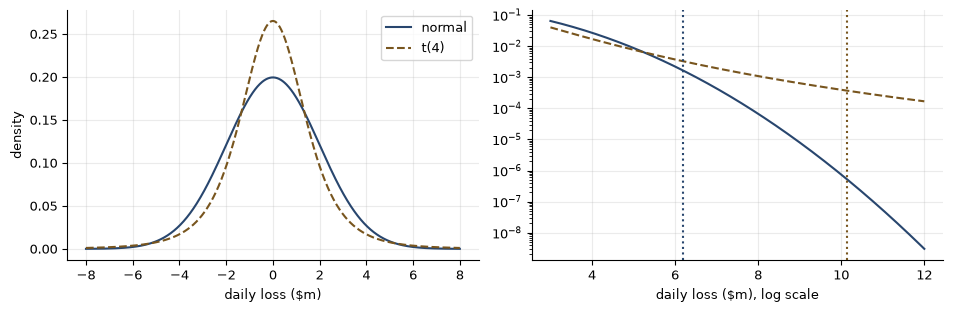

In [10]:
x = np.linspace(-8, 8, 801)
xt = np.linspace(3, 12, 400)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2))
axes[0].plot(x, norm.pdf(x, 0, SD), color=BLUE, label="normal")
axes[0].plot(x, student_t.pdf(x / SCALE, 4) / SCALE, color=AMBER, ls="--", label="t(4)")
axes[0].set_xlabel("daily loss ($m)")
axes[0].set_ylabel("density")
axes[0].legend()
axes[1].semilogy(xt, norm.pdf(xt, 0, SD), color=BLUE)
axes[1].semilogy(xt, student_t.pdf(xt / SCALE, 4) / SCALE, color=AMBER, ls="--")
axes[1].axvline(SD * Ninv(0.999), color=BLUE, ls=":")
axes[1].axvline(VAR_TRUE, color=AMBER, ls=":")
axes[1].set_xlabel("daily loss ($m), log scale")
plt.tight_layout()
plt.show()

## 7. Three ways to estimate a quantile you cannot observe — Example 38.7

A risk manager sees only 500 days of losses from the book of Example 38.6 and has three ways to turn them into a
99.9% VaR: a normal fit, the empirical quantile, and peaks over threshold (the generalized Pareto law fitted by
maximum likelihood to the 25 excesses over the 26th-largest loss), then

$$\mathrm{VaR} = u + \frac{\psi}{\xi}\Bigl[\Bigl(\tfrac{n}{n_u}(1-c)\Bigr)^{-\xi} - 1\Bigr], \qquad
\mathrm{ES} = \frac{\mathrm{VaR} + \psi - \xi u}{1-\xi}.$$

The likelihood is maximized in one variable, $\vartheta = \xi/\psi$, as Technical Note 38 derives. The example
works through one window; the text after it repeats the calculation on 400. Those 400 windows are 200,000 losses,
too many to print, so they are generated here from a fixed seed, and a cell at the end of this section can write
them to a CSV file.

The chapter quotes the table, the expected shortfall's median and mean, and the share of windows that cannot reach the answer, $0.999^{500} = 61\%$.
The further statistics are printed here. In these 400 windows 218 have a maximum below the true VaR, 55%
against the 61% expected; the shortfall is 2.5 binomial standard errors, unusually far for one set of draws but
not a property of the method. The largest loss averages \$10.83m across windows against an exact expectation
of \$10.44m. And the peaks-over-threshold ES has its median below the truth and its mean above it because a
few windows fit a large $\hat{\xi}$ and divide by $1 - \hat{\xi}$; the worst, with $\hat{\xi} = 0.85$, reports
\$128m.

In [11]:
SEED, WINDOWS, DAYS, N_U, Q = 20261005, 400, 500, 25, 0.999
Z999 = Ninv(Q)
show("true 99.9% VaR ($m)", VAR_TRUE, 10.14, 5e-3)
show("true 99.9% ES ($m)", ES_TRUE, 13.70, 5e-3)


def window(rng, n=DAYS):
    """n daily losses, $m. Each is SCALE * Z / sqrt(W / 4): Z standard normal by Box-Muller,
    W chi-squared with 4 degrees of freedom as -2 ln(U1 U2). Only rng.random() is used."""
    out = []
    for _ in range(n):
        u1, u2 = 1.0 - rng.random(), rng.random()
        z = sqrt(-2 * log(u1)) * cos(2 * pi * u2)
        w = -2 * log((1.0 - rng.random()) * (1.0 - rng.random()))
        out.append(-SCALE * z / sqrt(w / 4.0))
    return out


def normal_fit(L):
    n = len(L)
    m = sum(L) / n
    s = sqrt(sum((v - m) ** 2 for v in L) / (n - 1))
    return m, s, m + Z999 * s


def empirical_q(L, q=Q):
    """The k-th smallest of n at percentile (k - 1)/(n - 1), interpolated linearly."""
    s = sorted(L)
    h = (len(s) - 1) * q
    i = int(h)
    return s[i] + (h - i) * (s[i + 1] - s[i])


def gpd_fit(y, xi_min=-0.5):
    """Maximum likelihood for the generalized Pareto law on excesses y, with xi >= -1/2.
    Profiled in theta = xi / beta: for fixed theta the best xi is mean ln(1 + theta y), which
    leaves l(theta) = -N ln(xi / theta) - N xi - N to maximize over one variable."""
    n = len(y)
    ybar = sum(y) / n

    def xi_of(th):
        return sum(log1p(th * v) for v in y) / n

    def ll(th):
        if th == 0.0:
            return -n * log(ybar) - n
        x = xi_of(th)
        return -n * log(x / th) - n * x - n

    lo, hi = -(1.0 - 1e-12) / max(y), 0.0
    for _ in range(200):                      # the theta at which xi(theta) = -1/2
        m = 0.5 * (lo + hi)
        if xi_of(m) < xi_min:
            lo = m
        else:
            hi = m
    grid = sorted(set([hi * (1 - k / 100.0) for k in range(101)] +
                      [10 ** (-4 + 7 * k / 200.0) / ybar for k in range(201)]))
    vals = [ll(t) for t in grid]
    k = max(range(len(grid)), key=lambda j: vals[j])
    a, b = grid[max(k - 1, 0)], grid[min(k + 1, len(grid) - 1)]
    g = (sqrt(5) - 1) / 2                     # golden-section search around the best grid point
    c, d = b - g * (b - a), a + g * (b - a)
    fc, fd = ll(c), ll(d)
    for _ in range(200):
        if fc > fd:
            b, d, fd = d, c, fc
            c = b - g * (b - a)
            fc = ll(c)
        else:
            a, c, fc = c, d, fd
            d = a + g * (b - a)
            fd = ll(d)
    th = 0.5 * (a + b)
    xi = xi_of(th) if th != 0.0 else 0.0
    beta = xi / th if th != 0.0 else ybar
    return beta, xi


def pot(L, q=Q):
    """Threshold at the 26th-largest loss, so 25 losses exceed it; then VaR and ES."""
    s = sorted(L)
    u = s[-N_U - 1]
    beta, xi = gpd_fit([v - u for v in s[-N_U:]])
    a = (len(L) / float(N_U)) * (1 - q)
    var = u + beta * (expm1(-xi * log(a)) / xi if abs(xi) > 1e-12 else -log(a))
    es = (var + beta - xi * u) / (1 - xi)
    return u, beta, xi, var, es

true 99.9% VaR ($m)                                     10.1444   book     10.1400   ok
true 99.9% ES ($m)                                      13.6984   book     13.7000   ok


Window 1, the 26 largest losses ($m), ranks down each column:
 7.2509    5.4179    3.7229    3.1511    3.0356
 6.8962    4.6913    3.7217    3.1395    3.0329
 6.1266    4.4446    3.5340    3.0841    3.0045
 5.9353    4.1928    3.4639    3.0812    2.9119
 5.7588    4.1022    3.3718    3.0789    2.8497
                                                         2.8481

window 1 mean loss ($m)                                 -0.0011   book     -0.0011   ok
window 1 standard deviation ($m)                         1.7953   book      1.7953   ok
normal-fit VaR ($m)                                      5.5469   book      5.5500   ok
empirical-quantile VaR ($m)                              7.0739   book      7.0700   ok
threshold u, 26th-largest loss ($m)                      2.8481   book      2.8481   ok
psi-hat (GPD scale)                                      1.1511   book      1.1511   ok
xi-hat                                                   0.0983   book      0.0983   ok
peaks-over-thresh

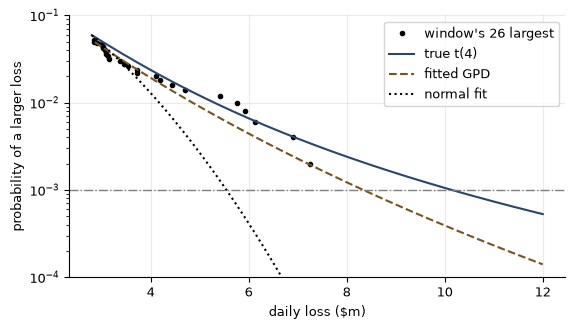

In [12]:
rng = random.Random(SEED)
W1 = window(rng)
top = sorted(W1, reverse=True)[:N_U + 1]
print("Window 1, the 26 largest losses ($m), ranks down each column:")
for r in range(5):
    print("   ".join("%7.4f" % top[r + 5 * c] for c in range(5)))
print("%55s %7.4f" % ("", top[25]))
print()
m1, s1, nv1 = normal_fit(W1)
u1, b1, x1, pv1, pe1 = pot(W1)
show("window 1 mean loss ($m)", m1, -0.0011, 5e-5)
show("window 1 standard deviation ($m)", s1, 1.7953, 5e-5)
show("normal-fit VaR ($m)", nv1, 5.55, 5e-3)
show("empirical-quantile VaR ($m)", empirical_q(W1), 7.07, 5e-3)
show("threshold u, 26th-largest loss ($m)", u1, 2.8481, 5e-5)
show("psi-hat (GPD scale)", b1, 1.1511, 5e-5)
show("xi-hat", x1, 0.0983, 5e-5)
show("peaks-over-threshold VaR ($m)", pv1, 8.34, 5e-3)
show("peaks-over-threshold ES ($m)", pe1, 10.21, 5e-3)

# Figure 38.3: the window's tail, P(L > x) on a log scale, against the true t(4) tail, the fitted
# generalized Pareto law and the normal fit. Each curve crosses 0.001 at its 99.9% VaR.
xs = np.linspace(2.8, 12, 300)
xg = xs[xs >= u1]
plt.semilogy(top, np.arange(1, N_U + 2) / DAYS, "k.", label="window's 26 largest")
plt.semilogy(xs, student_t.sf(xs / SCALE, 4), color=BLUE, label="true t(4)")
plt.semilogy(xg, (N_U / DAYS) * (1 + x1 * (xg - u1) / b1) ** (-1 / x1), color=AMBER, ls="--", label="fitted GPD")
plt.semilogy(xs, norm.sf((xs - m1) / s1), color="k", ls=":", label="normal fit")
plt.axhline(1 - Q, color="gray", ls="-.", lw=1)
plt.ylim(1e-4, 0.1)
plt.xlabel("daily loss ($m)")
plt.ylabel("probability of a larger loss")
plt.legend()
plt.show()

In [13]:
EMP, NRM, POTV, POTE, MAXL, XIS = [], [], [], [], [], []
rng = random.Random(SEED)                  # restart, so window 1 above is window 1 here
for k in range(WINDOWS):
    L = window(rng)
    EMP.append(empirical_q(L))
    NRM.append(normal_fit(L)[2])
    u, beta, xi, var, es = pot(L)
    POTV.append(var)
    POTE.append(es)
    XIS.append(xi)
    MAXL.append(max(L))

print("%-22s %10s %9s %9s %9s" % ("Method", "Mean VaR", "Bias %", "Spread", "S.e."))
for name, xs, m_p, b_p, s_p, se_p in (("Empirical quantile", EMP, 9.22, -9.1, 2.85, 0.14),
                                      ("Normal fit", NRM, 6.19, -39.0, 0.70, 0.03),
                                      ("Peaks over threshold", POTV, 10.11, -0.3, 3.32, 0.17)):
    m, s = np.mean(xs), np.std(xs, ddof=1)
    print("%-22s %10.2f %9.1f %9.2f %9.2f" % (name, m, 100 * (m / VAR_TRUE - 1), s, s / sqrt(WINDOWS)))
    show("  " + name + " mean ($m)", m, m_p, 5e-3)
    show("  " + name + " bias (%)", 100 * (m / VAR_TRUE - 1), b_p, 0.05)
    show("  " + name + " spread ($m)", s, s_p, 5e-3)
    show("  " + name + " s.e. ($m)", s / sqrt(WINDOWS), se_p, 5e-3)

show("POT ES, mean over windows ($m)", np.mean(POTE), 15.19, 5e-3)
show("POT ES, median window ($m)", np.median(POTE), 11.48, 5e-3)
kmax = int(np.argmax(POTE))
show("largest single POT ES ($m)", POTE[kmax], 128, 0.5)
show("  its xi-hat", XIS[kmax], 0.85, 5e-3)
show("P(window max < true VaR), exact (%)", 100 * Q ** DAYS, 61, 0.5)
below = sum(1 for x in MAXL if x < VAR_TRUE)
show("windows with max < true VaR", below, 218, 0)
show("  shortfall against 400 x 0.606, binomial s.e.",
     (WINDOWS * Q ** DAYS - below) / sqrt(WINDOWS * Q ** DAYS * (1 - Q ** DAYS)), 2.5, 0.05)
show("mean window maximum, simulated ($m)", np.mean(MAXL), 10.83, 5e-3)
# E[max] = integral of P(max > x) over x > 0, with P(max <= x) = F(x)^500.
emax = quad(lambda x: 1 - student_t.cdf(x / SCALE, 4) ** DAYS, 0, np.inf, limit=200)[0]
show("mean window maximum, exact ($m)", emax, 10.44, 5e-3)

Method                   Mean VaR    Bias %    Spread      S.e.
Empirical quantile           9.22      -9.1      2.85      0.14
  Empirical quantile mean ($m)                           9.2220   book      9.2200   ok
  Empirical quantile bias (%)                           -9.0930   book     -9.1000   ok
  Empirical quantile spread ($m)                         2.8468   book      2.8500   ok
  Empirical quantile s.e. ($m)                           0.1423   book      0.1400   ok
Normal fit                   6.19     -39.0      0.70      0.03
  Normal fit mean ($m)                                   6.1909   book      6.1900   ok
  Normal fit bias (%)                                  -38.9721   book    -39.0000   ok
  Normal fit spread ($m)                                 0.6997   book      0.7000   ok
  Normal fit s.e. ($m)                                   0.0350   book      0.0300   ok
Peaks over threshold        10.11      -0.3      3.32      0.17
  Peaks over threshold mean ($m)        

In [14]:
SAVE_CSV = False                           # set True to write all 400 x 500 losses to a file
if SAVE_CSV:
    rng = random.Random(SEED)
    with open("ch38_windows.csv", "w") as f:
        f.write("window,day,loss_musd\n")
        for k in range(WINDOWS):
            for d, v in enumerate(window(rng)):
                f.write("%d,%d,%.6f\n" % (k + 1, d + 1, v))
    print("wrote ch38_windows.csv: 200,000 rows")

## 8. One bad day, two forecasts — Example 38.8

A market at 1.00% daily volatility takes a $-3\%$ day. EWMA with $\lambda = 0.94$ and GARCH(1,1) with
$\omega = 0.000002$, $\alpha = 0.06$, $\beta = 0.93$ both update to about 1.22%. They differ in what comes next:
EWMA's forecast is flat, while GARCH reverts toward $V_L = \omega/(1-\alpha-\beta)$ at the rate $\alpha+\beta$,

$$\mathbb{E}[\sigma_{n+k}^2] = V_L + (\alpha+\beta)^k(\sigma_{n}^2 - V_L),$$

so a deviation halves in $\ln 0.5/\ln(\alpha+\beta) \approx 69$ trading days. The "average to horizon" is the mean
of these daily variances over the next $T$ trading days (3 months = 63, 1 year = 252), annualized with
$\sqrt{252}$.

EWMA (% daily)                                           1.2166   book      1.2166   ok
GARCH (% daily)                                          1.2207   book      1.2207   ok
rise in the estimate (%)                                22.0656   book     22.0000   ok
long-run daily volatility (%)                            1.4142   book      1.4142   ok
long-run annualized (%)                                 22.4499   book     22.4000   ok
half-life of a deviation (trading days)                 68.9676   book     69.0000   ok
Horizon      Days  GARCH ann.%   EWMA %
1 day           1        19.38    19.31
  GARCH average to 1 day (% ann.)                       19.3773   book     19.4000   ok
10 days        10        19.52    19.31
  GARCH average to 10 days (% ann.)                     19.5221   book     19.5000   ok
3 months       63        20.21    19.31
  GARCH average to 3 months (% ann.)                    20.2066   book     20.2000   ok
1 year        252        21.38    19.31
  GARCH 

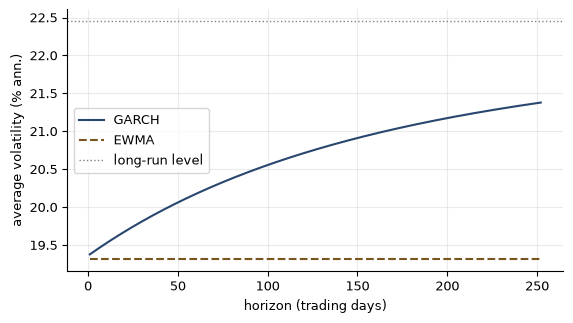

In [15]:
s0, u = 0.01, -0.03
lam, om, al, be = 0.94, 0.000002, 0.06, 0.93
ewma = lam * s0 ** 2 + (1 - lam) * u ** 2
garch = om + al * u ** 2 + be * s0 ** 2
VL = om / (1 - al - be)
show("EWMA (% daily)", 100 * sqrt(ewma), 1.2166, 5e-5)
show("GARCH (% daily)", 100 * sqrt(garch), 1.2207, 5e-5)
show("rise in the estimate (%)", 100 * (sqrt(garch) / s0 - 1), 22, 1.0)
show("long-run daily volatility (%)", 100 * sqrt(VL), 1.4142, 5e-5)
show("long-run annualized (%)", 100 * sqrt(252 * VL), 22.4, 0.05)
show("half-life of a deviation (trading days)", log(0.5) / log(al + be), 69, 0.5)


def garch_avg(T):
    """Average variance over the next T days, starting from today's updated variance."""
    return sum(VL + (al + be) ** k * (garch - VL) for k in range(T)) / T


print("%-10s %6s %12s %8s" % ("Horizon", "Days", "GARCH ann.%", "EWMA %"))
for T, lab, g_p in ((1, "1 day", 19.4), (10, "10 days", 19.5), (63, "3 months", 20.2), (252, "1 year", 21.4)):
    print("%-10s %6d %12.2f %8.2f" % (lab, T, 100 * sqrt(252 * garch_avg(T)), 100 * sqrt(252 * ewma)))
    show("  GARCH average to " + lab + " (% ann.)", 100 * sqrt(252 * garch_avg(T)), g_p, 0.05)
show("EWMA at every horizon (% ann.)", 100 * sqrt(252 * ewma), 19.3, 0.05)

T = np.arange(1, 253)
plt.plot(T, [100 * sqrt(252 * garch_avg(int(k))) for k in T], color=BLUE, label="GARCH")
plt.plot(T, 100 * sqrt(252 * ewma) * np.ones_like(T), color=AMBER, ls="--", label="EWMA")
plt.axhline(100 * sqrt(252 * VL), color="gray", ls=":", lw=1, label="long-run level")
plt.xlabel("horizon (trading days)")
plt.ylabel("average volatility (% ann.)")
plt.legend()
plt.show()

## 9. One number, revalued — Example 38.9

\$60m in asset A at 1.0% daily and \$40m in asset B at 2.5%. The cell recomputes the 99% one-day VaR as the correlation moves away from
the 0.30 the model was estimated with.

In [16]:
a, b = 60 * 0.010, 40 * 0.025          # dollar standard deviations, $m


def var2(rho, a=a, b=b):
    return z99 * sqrt(a * a + b * b + 2 * rho * a * b)


base = var2(0.30)
show("VaR at rho 0.30 ($m)", base, 3.051, 5e-4)
print("%-8s %10s %10s" % ("rho", "VaR $m", "change %"))
for rho, v_p, ch_p in ((-0.5, 2.028, -34), (0.0, 2.713, -11), (0.6, 3.355, 10), (0.9, 3.634, 19),
                       (1.0, 3.722, 22)):
    print("%-8.2f %10.3f %10.0f" % (rho, var2(rho), 100 * (var2(rho) / base - 1)))
    show("  VaR at rho %.2f ($m)" % rho, var2(rho), v_p, 5e-4)
    show("  change (%)", 100 * (var2(rho) / base - 1), ch_p, 0.5)

VaR at rho 0.30 ($m)                                     3.0510   book      3.0510   ok
rho          VaR $m   change %
-0.50         2.028        -34
  VaR at rho -0.50 ($m)                                  2.0281   book      2.0280   ok
  change (%)                                           -33.5274   book    -34.0000   ok
0.00          2.713        -11
  VaR at rho 0.00 ($m)                                   2.7130   book      2.7130   ok
  change (%)                                           -11.0788   book    -11.0000   ok
0.60          3.355         10
  VaR at rho 0.60 ($m)                                   3.3551   book      3.3550   ok
  change (%)                                             9.9683   book     10.0000   ok
0.90          3.634         19
  VaR at rho 0.90 ($m)                                   3.6339   book      3.6340   ok
  change (%)                                            19.1052   book     19.0000   ok
1.00          3.722         22
  VaR at rho 1.00 ($m)

## 10. Same margins, same correlation, different joint extremes — Example 38.10

Two variables with the same margins and correlation 0.50, joined first by a Gaussian copula and then by a $t$
copula with four degrees of freedom. The probability that both exceed their own $c$-quantile is computed by
quadrature, not simulation. For the $t$ case a bivariate $t_4$ is a bivariate normal divided by
$\sqrt{W/4}$ with $W \sim \chi^2_4$, so its joint tail is the Gaussian joint tail averaged over $W$. The upper tail
dependence coefficient of the $t$ copula is $\lambda = 2\,t_{\nu+1}\bigl(-\sqrt{(\nu+1)(1-\rho)/(1+\rho)}\bigr)$; the
Gaussian copula's is zero.

Figure 38.5 draws 1,500 joint outcomes from each copula. The draws use Python's `random.Random(38)`, so the
corner counts printed below are the chapter's on any machine.

In [17]:
RHO = 0.5
SR = sqrt(1 - RHO * RHO)


def gauss_joint(c):
    """P(Z1 > c, Z2 > c), standard bivariate normal with correlation RHO."""
    return quad(lambda x: phi(x) * (1 - N((c - RHO * x) / SR)), c, np.inf, epsabs=1e-13)[0]


def t_joint(q):
    """P(T1 > q, T2 > q), bivariate t(4): T = Z / sqrt(W/4), so T > q means Z > q sqrt(W/4)."""
    return quad(lambda w: chi2.pdf(w, 4) * gauss_joint(q * sqrt(w / 4.0)), 0, np.inf,
                epsabs=1e-13, limit=200)[0]


print("%-7s %11s %11s %7s" % ("c", "Gaussian", "t(4)", "ratio"))
ratios = []
for c, g_p, t_p, r_p in ((0.95, 0.01219, 0.01694, 1.39), (0.99, 0.001294, 0.002877, 2.22),
                         (0.995, 0.0004963, 0.001385, 2.79), (0.999, 0.00005426, 0.0002635, 4.86)):
    g, tj = gauss_joint(Ninv(c)), t_joint(student_t.ppf(c, 4))
    ratios.append(tj / g)
    print("%-7.3f %11.4g %11.4g %7.2f" % (c, g, tj, tj / g))
    show("  Gaussian, both beyond %.1fth" % (100 * c), g, g_p, 0.6 * 10 ** -len(repr(g_p).split(".")[1]))
    show("  t(4)", tj, t_p, 0.6 * 10 ** -len(repr(t_p).split(".")[1]))
    show("  ratio", tj / g, r_p, 5e-3)
show("upper tail dependence, t(4) copula", 2 * student_t.cdf(-sqrt(5 * (1 - RHO) / (1 + RHO)), 5), 0.2532, 5e-5)
show("conditional at 99.9th, Gaussian (%)", 100 * gauss_joint(Ninv(0.999)) / 0.001, 5.4, 0.05)
show("conditional at 99.9th, t(4) (%)", 100 * t_joint(student_t.ppf(0.999, 4)) / 0.001, 26.3, 0.05)

c          Gaussian        t(4)   ratio


0.950       0.01219     0.01694    1.39
  Gaussian, both beyond 95.0th                           0.0122   book      0.0122   ok
  t(4)                                                   0.0169   book      0.0169   ok
  ratio                                                  1.3895   book      1.3900   ok


0.990      0.001294    0.002877    2.22
  Gaussian, both beyond 99.0th                           0.0013   book      0.0013   ok
  t(4)                                                   0.0029   book      0.0029   ok
  ratio                                                  2.2233   book      2.2200   ok


0.995     0.0004963    0.001385    2.79
  Gaussian, both beyond 99.5th                           0.0005   book      0.0005   ok
  t(4)                                                   0.0014   book      0.0014   ok
  ratio                                                  2.7906   book      2.7900   ok


0.999     5.426e-05   0.0002635    4.86
  Gaussian, both beyond 99.9th                           0.0001   book      0.0001   ok
  t(4)                                                   0.0003   book      0.0003   ok
  ratio                                                  4.8562   book      4.8600   ok
upper tail dependence, t(4) copula                       0.2532   book      0.2532   ok
conditional at 99.9th, Gaussian (%)                      5.4259   book      5.4000   ok


conditional at 99.9th, t(4) (%)                         26.3493   book     26.3000   ok


draws beyond both 95th, Gaussian                        16.0000   book     16.0000   ok


draws beyond both 95th, t(4)                            26.0000   book     26.0000   ok
draws beyond both 99th, Gaussian                         1.0000   book      1.0000   ok
draws beyond both 99th, t(4)                             7.0000   book      7.0000   ok


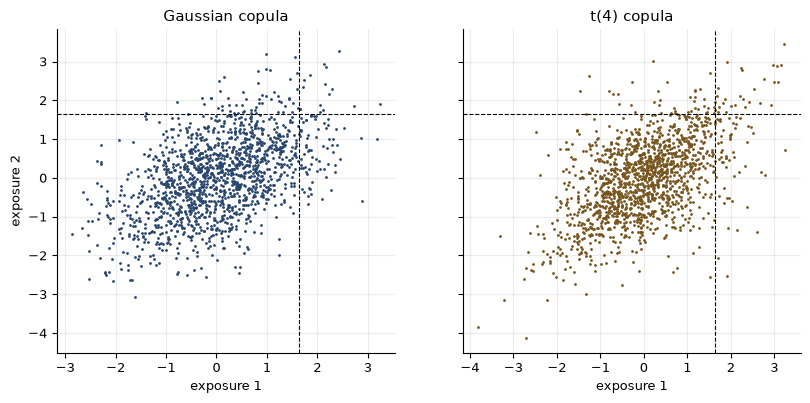

In [18]:
def copula_draws(n=1500, rho=RHO, seed=38):
    """Figure 38.5's draws: stdlib generator, so identical everywhere. The t(4) pair is two correlated
    normals over sqrt(W/4), W a sum of four squared normals, mapped to normal margins."""
    rng = random.Random(seed)
    g, t = [], []
    c_ = sqrt(1 - rho * rho)
    for _ in range(n):
        z1 = rng.gauss(0, 1); z2 = rho * z1 + c_ * rng.gauss(0, 1)
        g.append((z1, z2))
        y1 = rng.gauss(0, 1); y2 = rho * y1 + c_ * rng.gauss(0, 1)
        w = sum(rng.gauss(0, 1) ** 2 for _ in range(4)) / 4
        t.append((Ninv(student_t.cdf(y1 / sqrt(w), 4)), Ninv(student_t.cdf(y2 / sqrt(w), 4))))
    return np.array(g), np.array(t)


SG, ST = copula_draws()
for q, g_p, t_p in ((0.95, 16, 26), (0.99, 1, 7)):
    k = Ninv(q)
    show("draws beyond both %dth, Gaussian" % (100 * q), np.sum((SG[:, 0] > k) & (SG[:, 1] > k)), g_p, 0)
    show("draws beyond both %dth, t(4)" % (100 * q), np.sum((ST[:, 0] > k) & (ST[:, 1] > k)), t_p, 0)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2), sharey=True)
for ax, pts, col, title in ((axes[0], SG, BLUE, "Gaussian copula"), (axes[1], ST, AMBER, "t(4) copula")):
    ax.plot(pts[:, 0], pts[:, 1], ".", ms=2, color=col)
    ax.axvline(Ninv(0.95), color="k", ls="--", lw=0.8)
    ax.axhline(Ninv(0.95), color="k", ls="--", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("exposure 1")
axes[0].set_ylabel("exposure 2")
plt.show()

## 11. Three factors, two portfolios, two verdicts — Example 38.11

The cell takes the nine tenors, the daily rate-change volatilities and the directional book's sensitivities the
example prints, and the correlation $\rho_{ij} = 0.7 + 0.3\,e^{-0.3\lvert\ln T_i - \ln T_j\rvert}$. Keeping $k$ factors replaces a
book's variance $\mathbf{w}^\top\Sigma\mathbf{w}$ by $\sum_{j\le k}\ell_j (\mathbf{v}_j^\top \mathbf{w})^2$. The table reports the share of each book's
*own* variance that survives, which is the like-for-like comparison with the curve's 96.88%. The VaRs use the
unrounded quantile; Figure 38.6 draws the three leading factors beside the butterfly.

correlation, 3 months with 30 years                      0.7713   book      0.7700   ok
factor 1 share of curve variance (%)                    90.9786   book     90.9800   ok
  cumulative (%)                                        90.9786   book     90.9800   ok
factor 2 share of curve variance (%)                     3.9406   book      3.9400   ok
  cumulative (%)                                        94.9192   book     94.9200   ok
factor 3 share of curve variance (%)                     1.9565   book      1.9600   ok
  cumulative (%)                                        96.8757   book     96.8800   ok
factor 4 share of curve variance (%)                     1.0993   book      1.1000   ok
  cumulative (%)                                        97.9749   book     97.9700   ok
Factors     Dir VaR $  Var kept   Bfly VaR $  Var kept
  directional, 1 factors: VaR ($)                   795376.8735   book 795377.0000   ok
  directional, 1 factors: variance kept (%)             98.6977  

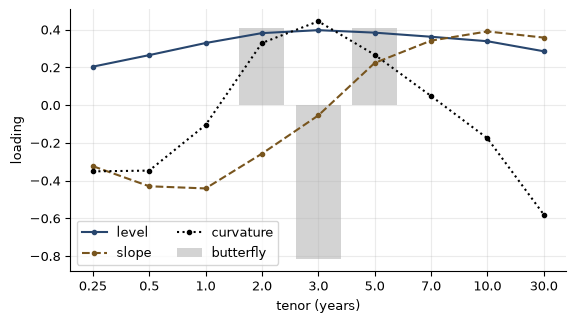

In [19]:
tenors = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 30])
vol_bp = np.array([3.5, 4.4, 5.3, 6.0, 6.2, 6.0, 5.7, 5.4, 4.8])
lnT = np.log(tenors)
corr = 0.7 + 0.3 * np.exp(-0.3 * np.abs(lnT[:, None] - lnT[None, :]))
cov = np.outer(vol_bp, vol_bp) * corr
lam_, V = np.linalg.eigh(cov)
lam_, V = lam_[::-1], V[:, ::-1]
show("correlation, 3 months with 30 years", corr[0, 8], 0.77, 5e-3)
for k, (sh_p, cum_p) in enumerate(((90.98, 90.98), (3.94, 94.92), (1.96, 96.88), (1.10, 97.97))):
    show("factor %d share of curve variance (%%)" % (k + 1), 100 * lam_[k] / lam_.sum(), sh_p, 5e-3)
    show("  cumulative (%)", 100 * lam_[:k + 1].sum() / lam_.sum(), cum_p, 5e-3)

directional = np.array([10, 5, -8, 15, 12, -10, 20, 18, 6]) * 1000.0     # $ per bp
butterfly = np.zeros(9)
butterfly[[3, 4, 5]] = [20000, -40000, 20000]
print("%-8s %12s %9s %12s %9s" % ("Factors", "Dir VaR $", "Var kept", "Bfly VaR $", "Var kept"))
book = {1: (795377, 98.7, 20390, 3.0), 2: (797262, 99.2, 23225, 3.9), 3: (797364, 99.2, 38194, 10.5),
        5: (797380, 99.2, 62434, 28.0), 9: (800607, 100.0, 117925, 100.0)}
for k, (dv_p, ds_p, bv_p, bs_p) in book.items():
    row = []
    for s, v_p, sh_p, nm in ((directional, dv_p, ds_p, "directional"), (butterfly, bv_p, bs_p, "butterfly")):
        kept = sum(lam_[j] * (V[:, j] @ s) ** 2 for j in range(k))
        row += [z99 * sqrt(kept), 100 * kept / (s @ cov @ s)]
        show("  %s, %d factors: VaR ($)" % (nm, k), z99 * sqrt(kept), v_p, 0.5)
        show("  %s, %d factors: variance kept (%%)" % (nm, k), 100 * kept / (s @ cov @ s), sh_p, 0.05)
    print("%-8d %12.0f %9.1f %12.0f %9.1f" % (k, *row))

# Figure 38.6: loadings signed so level is positive, slope rises to the long end, curvature is positive at 3y.
sgn = [np.sign(V[:, 0].sum()), np.sign(V[8, 1] - V[0, 1]), np.sign(V[4, 2])]
pos = np.arange(1, 10)
plt.bar(pos[3:6], butterfly[3:6] / np.linalg.norm(butterfly), color="lightgray", label="butterfly")
for j, (col, ls, nm) in enumerate(((BLUE, "-", "level"), (AMBER, "--", "slope"), ("k", ":", "curvature"))):
    plt.plot(pos, sgn[j] * V[:, j], color=col, ls=ls, marker="o", ms=3, label=nm)
plt.xticks(pos, [str(x) for x in tenors])
plt.xlabel("tenor (years)")
plt.ylabel("loading")
plt.legend(ncol=2)
plt.show()

## 12. Scaling and stress — Sections 38.14 and 38.18

The square-root-of-time rule assumes independent daily losses. With first-order autocorrelation $\rho$, the
variance of an $h$-day sum is $\sigma^2\bigl(h + 2\sum_{k=1}^{h-1}(h-k)\rho^k\bigr)$, so the rule understates the
ten-day VaR when $\rho > 0$ and overstates it when $\rho < 0$. The "Error" column is (square-root rule − true)/true.
Then the stressed book of Section 38.18: the same \$100m at 99%, at a calm 1.0% and a stressed 3.2% daily
volatility.

In [20]:
v1d = SD * z99


def scaled(r, h=10):
    return v1d * sqrt(h + 2 * sum((h - k) * r ** k for k in range(1, h)))


root = scaled(0.0)
show("10-day VaR, autocorrelation 0 ($m)", root, 14.71, 5e-3)
for r, v_p, e_p in ((0.10, 16.10, -9), (0.25, 18.48, -20)):
    show("10-day VaR, autocorrelation %.2f ($m)" % r, scaled(r), v_p, 5e-3)
    show("  error, against the true figure (%)", 100 * (root - scaled(r)) / scaled(r), e_p, 0.5)
show("calm, 1.0% daily ($m)", 100 * 0.010 * z99, 2.33, 5e-3)
show("stressed, 3.2% daily ($m)", 100 * 0.032 * z99, 7.44, 5e-3)

10-day VaR, autocorrelation 0 ($m)                      14.7131   book     14.7100   ok
10-day VaR, autocorrelation 0.10 ($m)                   16.1008   book     16.1000   ok
  error, against the true figure (%)                    -8.6188   book     -9.0000   ok
10-day VaR, autocorrelation 0.25 ($m)                   18.4811   book     18.4800   ok
  error, against the true figure (%)                   -20.3883   book    -20.0000   ok
calm, 1.0% daily ($m)                                    2.3263   book      2.3300   ok
stressed, 3.2% daily ($m)                                7.4443   book      7.4400   ok


## 13. Sixty percent of the money, thirty percent of the risk — Example 38.12

The book of Example 38.9 at $\rho = 0.30$. Marginal VaR is $\partial\mathrm{VaR}/\partial w_i = z\,(\Sigma\mathbf{w})_i/\sigma_P$,
the VaR added per dollar. Component VaR is the Euler allocation $w_i\,\partial\mathrm{VaR}/\partial w_i$, and the
components add up to the VaR exactly.

In [21]:
sp = sqrt(a * a + b * b + 2 * 0.3 * a * b)
cA = z99 * (a * a + 0.3 * a * b) / sp
cB = z99 * (b * b + 0.3 * a * b) / sp
show("standalone A ($m)", z99 * a, 1.396, 5e-4)
show("standalone B ($m)", z99 * b, 2.326, 5e-4)
show("standalone sum ($m)", z99 * (a + b), 3.722, 5e-4)
show("component A ($m)", cA, 0.958, 5e-4)
show("component B ($m)", cB, 2.093, 5e-4)
show("components sum to the VaR ($m)", cA + cB, 3.051, 5e-4)
show("share A (%)", 100 * cA / (cA + cB), 31.4, 0.05)
show("share B (%)", 100 * cB / (cA + cB), 68.6, 0.05)
show("diversification benefit (%)", 100 * (1 - (cA + cB) / (z99 * (a + b))), 18.0, 0.05)
show("marginal VaR of A (per $)", cA / 60, 0.0160, 5e-5)
show("marginal VaR of B (per $)", cB / 40, 0.0523, 5e-5)
Sw = np.array([60 * 0.01 ** 2 + 40 * 0.3 * 0.01 * 0.025, 60 * 0.3 * 0.01 * 0.025 + 40 * 0.025 ** 2])
show("Sigma w, A (return units)", Sw[0], 0.0090, 5e-7)
show("Sigma w, B (return units)", Sw[1], 0.0295, 5e-7)
show("marginal A from z (Sigma w)_A / sigma_P", z99 * Sw[0] / sp, 0.0160, 5e-5)
show("move $10m from A to B: rise in VaR (%)", 100 * (var2(0.3, 50 * 0.010, 50 * 0.025) / base - 1), 12.8, 0.05)
show("incremental VaR of B ($m)", base - z99 * a, 1.655, 5e-4)
show("incremental VaR of A ($m)", base - z99 * b, 0.725, 5e-4)
show("  their sum, not the total ($m)", 2 * base - z99 * (a + b), 2.380, 5e-4)

standalone A ($m)                                        1.3958   book      1.3960   ok
standalone B ($m)                                        2.3263   book      2.3260   ok
standalone sum ($m)                                      3.7222   book      3.7220   ok
component A ($m)                                         0.9579   book      0.9580   ok
component B ($m)                                         2.0931   book      2.0930   ok
components sum to the VaR ($m)                           3.0510   book      3.0510   ok
share A (%)                                             31.3953   book     31.4000   ok
share B (%)                                             68.6047   book     68.6000   ok
diversification benefit (%)                             18.0320   book     18.0000   ok
marginal VaR of A (per $)                                0.0160   book      0.0160   ok
marginal VaR of B (per $)                                0.0523   book      0.0523   ok
Sigma w, A (return units)       

## 14. Two hundred and fifty days is not much evidence — Example 38.13

A correct 99% VaR model is breached on each of 250 days with probability 1%, so the exception count is
Binomial(250, 0.01). Kupiec's likelihood-ratio statistic

$$\mathrm{LR} = -2\Bigl[(n-x)\ln c + x\ln(1-c) - (n-x)\ln(1-\hat p) - x\ln\hat p\Bigr], \qquad \hat p = x/n,$$

is compared with the 95% point of $\chi^2_1$, 3.841. The Basel traffic light is green for 0–4 exceptions, yellow
for 5–9, red for 10 or more.

expected exceptions                                      2.5000   book      2.5000   ok
chi-square(1) 95% critical value                         3.8415   book      3.8410   ok
Exceptions      Prob    Kupiec   Reject     Zone
0             0.0811      5.03      yes    green
  P(0 exceptions)                                        0.0811   book      0.0811   ok
  Kupiec LR                                              5.0252   book      5.0300   ok
1             0.2047      1.18       no    green
  P(1 exceptions)                                        0.2047   book      0.2047   ok
  Kupiec LR                                              1.1765   book      1.1800   ok
2             0.2574      0.11       no    green
  P(2 exceptions)                                        0.2574   book      0.2574   ok
  Kupiec LR                                              0.1084   book      0.1100   ok
3             0.2149      0.09       no    green
  P(3 exceptions)                                  

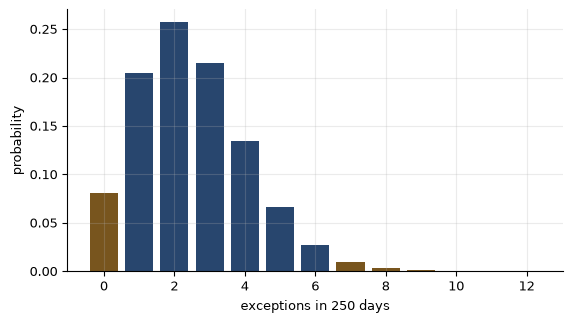

In [22]:
n, pb = 250, 0.01


def kupiec(x):
    ph = x / float(n)
    l0 = (n - x) * log(1 - pb) + x * log(pb)
    l1 = ((n - x) * log(1 - ph) if x < n else 0.0) + (x * log(ph) if x else 0.0)
    return -2 * (l0 - l1)


crit = chi2.ppf(0.95, 1)
show("expected exceptions", n * pb, 2.5, 1e-9)
show("chi-square(1) 95% critical value", crit, 3.841, 5e-4)
print("%-11s %8s %9s %8s %8s" % ("Exceptions", "Prob", "Kupiec", "Reject", "Zone"))
for x, pr_p, lr_p in ((0, 0.0811, 5.03), (1, 0.2047, 1.18), (2, 0.2574, 0.11), (3, 0.2149, 0.09),
                      (4, 0.1341, 0.77), (5, 0.0666, 1.96), (7, 0.0097, 5.50), (10, 0.0002, 12.96)):
    zone = "green" if x <= 4 else ("yellow" if x <= 9 else "red")
    print("%-11d %8.4f %9.2f %8s %8s" % (x, binom.pmf(x, n, pb), kupiec(x),
                                       "yes" if kupiec(x) > crit else "no", zone))
    show("  P(%d exceptions)" % x, binom.pmf(x, n, pb), pr_p, 5e-5)
    show("  Kupiec LR", kupiec(x), lr_p, 5e-3)
acc = [x for x in range(15) if kupiec(x) <= crit]
show("Kupiec accepts from (exceptions)", min(acc), 1, 0)
show("Kupiec accepts up to (exceptions)", max(acc), 6, 0)
show("  as coverage, lowest count (%)", 100 * (1 - min(acc) / float(n)), 99.6, 5e-3)
show("  as coverage, highest count (%)", 100 * (1 - max(acc) / float(n)), 97.6, 5e-3)
show("correct model in yellow or worse (%)", 100 * binom.sf(4, n, pb), 10.8, 0.05)
show("97% model flagged by the zones (%)", 100 * binom.sf(4, n, 0.03), 87, 0.5)
show("97% model rejected by Kupiec, 0 or >= 7 (%)", 100 * (binom.pmf(0, n, 0.03) + binom.sf(6, n, 0.03)), 63, 0.5)

k = np.arange(0, 13)
colors = [BLUE if kupiec(int(j)) <= crit else AMBER for j in k]
plt.bar(k, binom.pmf(k, n, pb), color=colors)
plt.xlabel("exceptions in 250 days")
plt.ylabel("probability")
plt.show()

## 15. Stress testing — Examples 38.14 and 38.15, Figure 38.8

The book of Example 38.9 under a liquidation scenario in which both assets fall four of their own daily
standard deviations, then the reverse question: of all moves that lose the same \$6.4m, which is the most
plausible, the one where the joint density is highest? For a linear book with normal factors the answer is

$$\mathbf{r}^* = -l\,\frac{\Sigma\mathbf{w}}{\mathbf{w}^\top\Sigma\mathbf{w}},$$

which lies $l/\sigma_P$ standard deviations from the center, measured by the Mahalanobis distance
$\sqrt{\mathbf{r}^\top\Sigma^{-1}\mathbf{r}}$.

portfolio daily standard deviation ($m)                  1.3115   book      1.3110   ok
scenario loss ($m)                                       6.4000   book      6.4000   ok
  multiple of the 99% VaR                                2.0977   book      2.1000   ok
sensitivity report's worst case short by (%)            37.5000   book     37.5000   ok
scenario in standard deviations                          4.8800   book      4.8800   ok
  once in this many years                             7539.3138   book   7500.0000   ok
r*_A (%)                                                -3.3488   book     -3.3500   ok
r*_B (%)                                               -10.9767   book    -10.9800   ok
distance of r* (s.d.)                                    4.8800   book      4.8800   ok
distance of the hand-written scenario (s.d.)             4.9614   book      4.9600   ok
density ratio, r* to hand-written                        1.4929   book      1.5000   ok


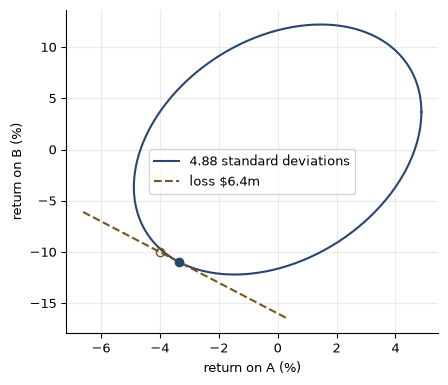

In [23]:
w_ab = np.array([60.0, 40.0])                          # $m
vol_ab = np.array([0.010, 0.025])
cov_ab = np.outer(vol_ab, vol_ab) * np.array([[1, 0.3], [0.3, 1]])
sig_ab = sqrt(w_ab @ cov_ab @ w_ab)
scen = np.array([-0.04, -0.10])
loss = -(w_ab @ scen)
show("portfolio daily standard deviation ($m)", sig_ab, 1.311, 5e-4)
show("scenario loss ($m)", loss, 6.4, 1e-9)
show("  multiple of the 99% VaR", loss / base, 2.10, 5e-3)
show("sensitivity report's worst case short by (%)", 100 * (1 - 4.0 / loss), 37.5, 1e-9)
show("scenario in standard deviations", loss / sig_ab, 4.88, 5e-3)
show("  once in this many years", 1 / norm.sf(loss / sig_ab) / 250, 7500, 100)

r_star = -loss * (cov_ab @ w_ab) / (w_ab @ cov_ab @ w_ab)
dist = lambda r: sqrt(r @ np.linalg.solve(cov_ab, r))
show("r*_A (%)", 100 * r_star[0], -3.35, 5e-3)
show("r*_B (%)", 100 * r_star[1], -10.98, 5e-3)
show("distance of r* (s.d.)", dist(r_star), 4.88, 5e-3)
show("distance of the hand-written scenario (s.d.)", dist(scen), 4.96, 5e-3)
show("density ratio, r* to hand-written", exp((dist(scen) ** 2 - dist(r_star) ** 2) / 2), 1.49, 5e-3)

t_ = np.linspace(0, 2 * pi, 361)
C = np.linalg.cholesky(cov_ab) * 100                  # in percent
ell = dist(r_star) * C @ np.vstack([np.cos(t_), np.sin(t_)])
xa = np.linspace(-6.6, 0.33, 2)
plt.figure(figsize=(4.8, 4.2))
plt.plot(ell[0], ell[1], color=BLUE, label="4.88 standard deviations")
plt.plot(xa, -16 - 1.5 * xa, color=AMBER, ls="--", label="loss $6.4m")
plt.plot(100 * r_star[0], 100 * r_star[1], "o", color=BLUE)
plt.plot(-4, -10, "o", mfc="none", color=AMBER)
plt.xlabel("return on A (%)")
plt.ylabel("return on B (%)")
plt.legend()
plt.show()

## 16. Twenty-five sigma, several days running — case study

The cell computes the probability that a standard normal exceeds 25 from the Mills ratio $1 - N(x) \approx N'(x)/x$, which is
accurate this far out.

In [24]:
log10_tail = (-0.5 * 625 - log(25 * sqrt(2 * pi))) / log(10)
show("log10 P(Z > 25)", log10_tail, -138, 0.5)
show("  scipy's log survival function, for comparison", norm.logsf(25) / log(10), -138, 0.5)

log10 P(Z > 25)                                       -137.5141   book   -138.0000   ok
  scipy's log survival function, for comparison       -137.5147   book   -138.0000   ok


In [25]:
if BAD:
    print("%d figure(s) differ from the chapter:" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("every checked figure in the chapter reproduces.")

every checked figure in the chapter reproduces.
